In [5]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np


In [6]:
torch.__version__


'2.14.0+cpu'

In [8]:
torch.manual_seed(42)
np.random.seed(42)


In [9]:
mnist_transform=transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

In [10]:
mnist_full = datasets.MNIST(root='./data', train=True, download=True, transform=mnist_transform)


In [11]:
mnist_test = datasets.MNIST(root='./data', train=False, download=True, transform=mnist_transform)

In [13]:
mnist_train, mnist_val = random_split(mnist_full, [50000, 10000], generator=torch.Generator().manual_seed(42))

In [14]:
BATCH_SIZE = 128

In [15]:
mnist_train_loader = DataLoader(mnist_train, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=False)

In [16]:
mnist_test_loader = DataLoader(mnist_test, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=False)

In [17]:
mnist_val_loader = DataLoader(mnist_val, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=False)

In [18]:
len(mnist_train)

50000

In [19]:
len(mnist_test)

10000

In [20]:
len(mnist_val)

10000

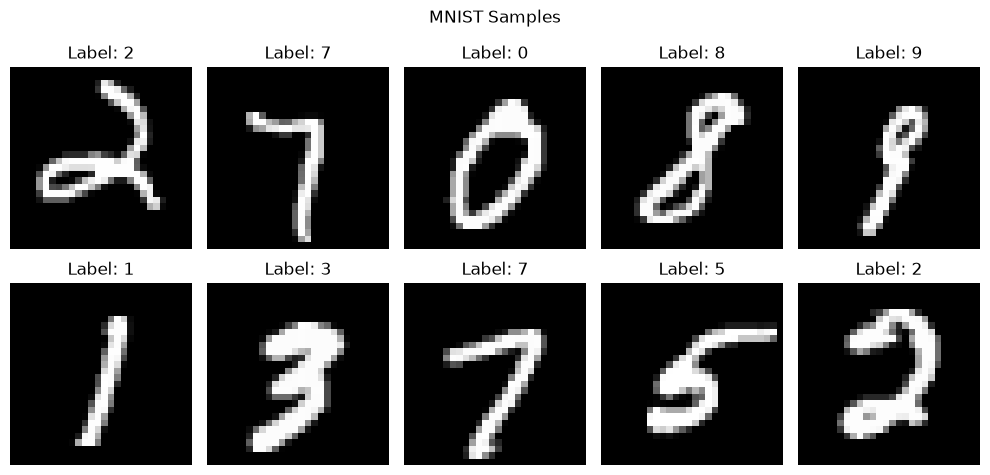

In [21]:
images, labels = next(iter(mnist_train_loader))

plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(images[i].squeeze(), cmap="gray")
    plt.title(f"Label: {labels[i].item()}")
    plt.axis("off")

plt.suptitle("MNIST Samples")
plt.tight_layout()
plt.show()


In [38]:
class CNN(nn.Module):

    def __init__(self, in_channels, num_classes, image_size):
        super().__init__()

        self.conv1 = nn.Conv2d(
            in_channels,
            32,
            kernel_size=3,
            padding=1
        )

        self.bn1 = nn.BatchNorm2d(32)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(2, 2)


        self.conv2 = nn.Conv2d(
            32,
            64,
            kernel_size=3,
            padding=1
        )

        self.bn2 = nn.BatchNorm2d(64)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(2, 2)

        with torch.no_grad():
            dummy = torch.zeros(
                1, in_channels, image_size, image_size
            )

            dummy = self.pool1(
                self.relu1(
                    self.bn1(
                        self.conv1(dummy)
                    )
                )
            )

            dummy = self.pool2(
                self.relu2(
                    self.bn2(
                        self.conv2(dummy)
                    )
                )
            )

            flattened_size = dummy.view(1, -1).shape[1]

        print(
            f"Flattened feature size for {image_size}x{image_size}:",
            flattened_size
        )


        self.fc1 = nn.Linear(
            flattened_size,
            128
        )

        self.relu3 = nn.ReLU()

        self.dropout = nn.Dropout(p=0.3)

        self.fc2 = nn.Linear(
            128,
            num_classes
        )

    def forward(self, x):

       
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu1(x)
        x = self.pool1(x)

        x = self.conv2(x)
        x = self.bn2(x)
        x = self.relu2(x)
        x = self.pool2(x)

   
        x = torch.flatten(x, start_dim=1)

    
        x = self.fc1(x)
        x = self.relu3(x)
        x = self.dropout(x)

        x = self.fc2(x)

        return x
mnist_model = CNN(
    in_channels=1,
    num_classes=10,
    image_size=28
)

print("\nMNIST MODEL")
print(mnist_model)

Flattened feature size for 28x28: 3136

MNIST MODEL
CNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=3136, out_features=128, bias=True)
  (relu3): ReLU()
  (dropout): Dropout(p=0.3, inplace=False)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


In [27]:
sample_images, _ = next(iter(mnist_train_loader))
sample_images = sample_images[:4]

with torch.no_grad():
    x = mnist_model.conv1(sample_images)
    print("After Conv1:   ", x.shape)

    x = mnist_model.bn1(x)
    x = mnist_model.relu1(x)
    x = mnist_model.pool1(x)
    print("After Pool1:   ", x.shape)

    x = mnist_model.conv2(x)
    print("After Conv2:   ", x.shape)

    x = mnist_model.bn2(x)
    x = mnist_model.relu2(x)
    x = mnist_model.pool2(x)
    print("After Pool2:   ", x.shape)

    x = torch.flatten(x, start_dim=1)
    print("After Flatten: ", x.shape)

After Conv1:    torch.Size([4, 32, 28, 28])
After Pool1:    torch.Size([4, 32, 14, 14])
After Conv2:    torch.Size([4, 64, 14, 14])
After Pool2:    torch.Size([4, 64, 7, 7])
After Flatten:  torch.Size([4, 3136])


In [28]:
def train_one_epoch(model, loader, criterion, optimizer):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

    
        optimizer.zero_grad()

    
        outputs = model(images)

    
        loss = criterion(outputs, labels)

        
        loss.backward()


        optimizer.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    return running_loss / total, 100 * correct / total

In [29]:
def evaluate(model, loader, criterion):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

  
    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    return running_loss / total, 100 * correct / total

In [30]:
def train_model(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    epochs
):

    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": []
    }

    for epoch in range(epochs):

        train_loss, train_acc = train_one_epoch(
            model, train_loader, criterion, optimizer
        )

        val_loss, val_acc = evaluate(
            model, val_loader, criterion
        )

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)

        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        print(
            f"Epoch [{epoch+1}/{epochs}] | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc:.2f}% | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc:.2f}%"
        )

    return history

In [32]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
mnist_model = mnist_model.to(device)

print("Using device:", device)

Using device: cpu


In [33]:
criterion = nn.CrossEntropyLoss()

mnist_optimizer = optim.Adam(
    mnist_model.parameters(),
    lr=0.001
)

MNIST_EPOCHS = 5

print("=" * 70)
print("TRAINING CNN ON MNIST")
print("=" * 70)

mnist_history = train_model(
    mnist_model,
    mnist_train_loader,
    mnist_val_loader,
    criterion,
    mnist_optimizer,
    MNIST_EPOCHS
)

mnist_test_loss, mnist_test_acc = evaluate(
    mnist_model,
    mnist_test_loader,
    criterion
)

print("\nMNIST Test Loss:", round(mnist_test_loss, 4))
print("MNIST Test Accuracy:", round(mnist_test_acc, 2), "%")


TRAINING CNN ON MNIST
Epoch [1/5] | Train Loss: 0.1861 | Train Acc: 94.26% | Val Loss: 0.0726 | Val Acc: 97.61%
Epoch [2/5] | Train Loss: 0.0656 | Train Acc: 97.97% | Val Loss: 0.0510 | Val Acc: 98.42%
Epoch [3/5] | Train Loss: 0.0492 | Train Acc: 98.47% | Val Loss: 0.0428 | Val Acc: 98.79%
Epoch [4/5] | Train Loss: 0.0416 | Train Acc: 98.71% | Val Loss: 0.0400 | Val Acc: 98.80%
Epoch [5/5] | Train Loss: 0.0357 | Train Acc: 98.86% | Val Loss: 0.0451 | Val Acc: 98.70%

MNIST Test Loss: 0.032
MNIST Test Accuracy: 99.01 %


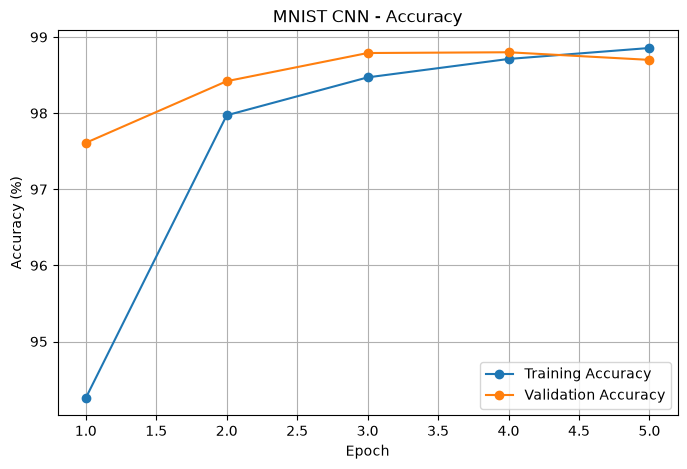

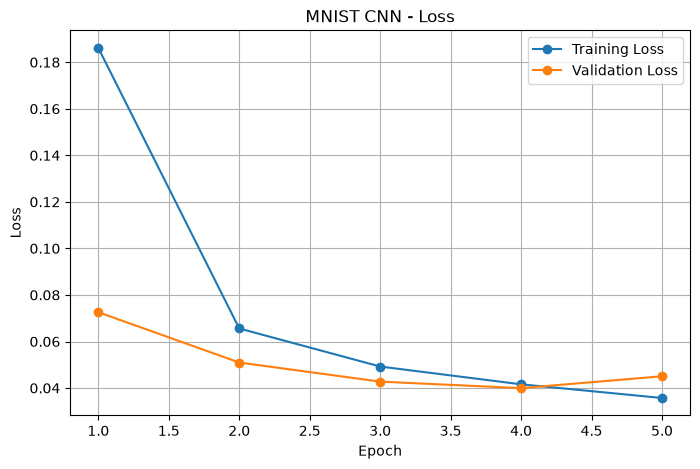

In [34]:
epochs_range = range(1, MNIST_EPOCHS + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs_range, mnist_history["train_acc"],
         marker="o", label="Training Accuracy")
plt.plot(epochs_range, mnist_history["val_acc"],
         marker="o", label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("MNIST CNN - Accuracy")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(epochs_range, mnist_history["train_loss"],
         marker="o", label="Training Loss")
plt.plot(epochs_range, mnist_history["val_loss"],
         marker="o", label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("MNIST CNN - Loss")
plt.legend()
plt.grid(True)
plt.show()

Conv1 filter tensor shape: torch.Size([32, 1, 3, 3])


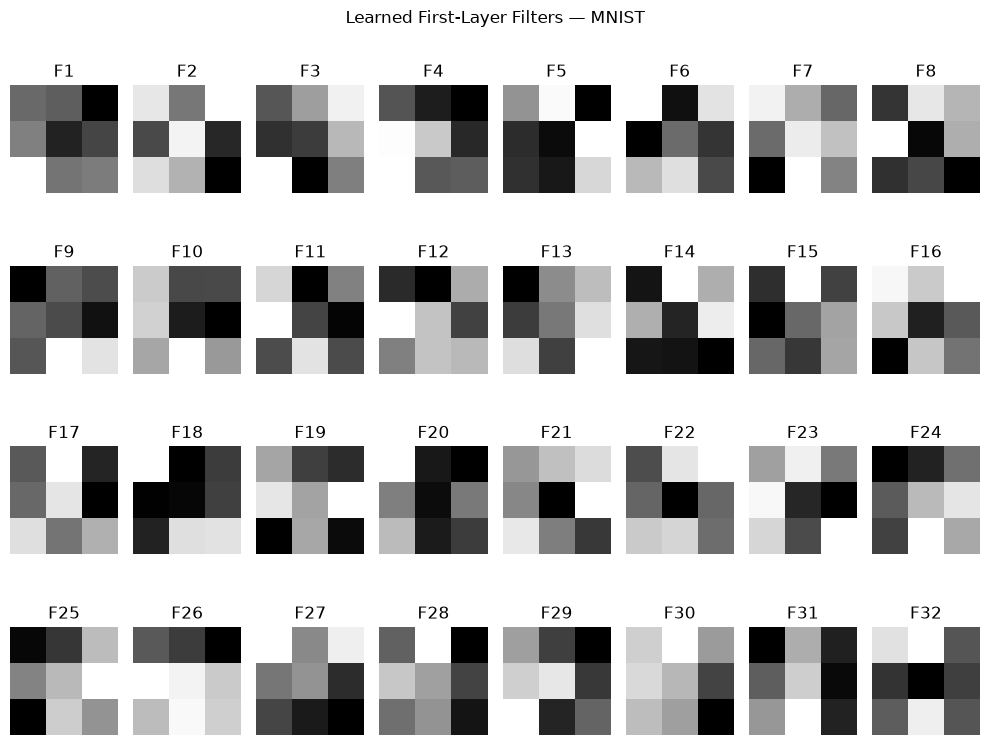

In [35]:
filters = mnist_model.conv1.weight.detach().cpu()

print("Conv1 filter tensor shape:", filters.shape)

plt.figure(figsize=(10, 8))

for i in range(32):

    plt.subplot(4, 8, i + 1)
    plt.imshow(filters[i, 0], cmap="gray")
    plt.title(f"F{i+1}")
    plt.axis("off")

plt.suptitle("Learned First-Layer Filters — MNIST")
plt.tight_layout()
plt.show()


Actual digit: 7
Feature map shape: torch.Size([32, 28, 28])


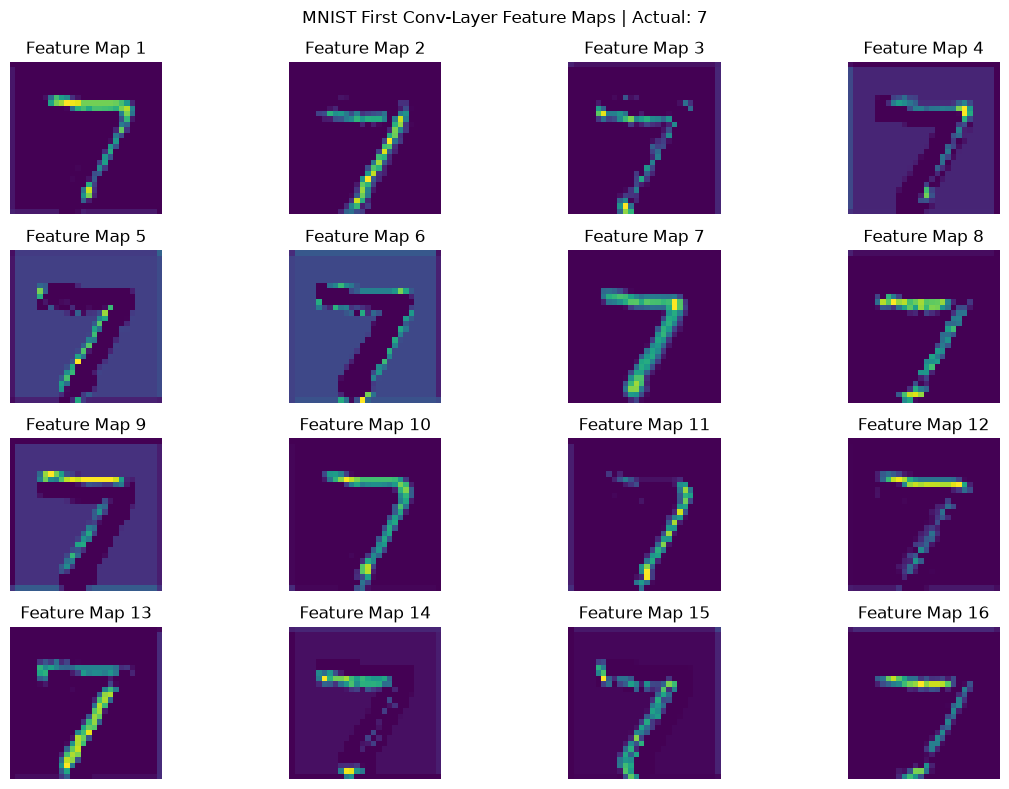

In [36]:
sample_image, sample_label = mnist_test[0]
sample_input = sample_image.unsqueeze(0).to(device)

mnist_model.eval()

with torch.no_grad():

    feature_maps = mnist_model.conv1(sample_input)
    feature_maps = mnist_model.bn1(feature_maps)
    feature_maps = mnist_model.relu1(feature_maps)

feature_maps = feature_maps.cpu().squeeze(0)

print("Actual digit:", sample_label)
print("Feature map shape:", feature_maps.shape)

plt.figure(figsize=(12, 8))

for i in range(16):

    plt.subplot(4, 4, i + 1)
    plt.imshow(feature_maps[i], cmap="viridis")
    plt.title(f"Feature Map {i+1}")
    plt.axis("off")

plt.suptitle(
    f"MNIST First Conv-Layer Feature Maps | Actual: {sample_label}"
)

plt.tight_layout()
plt.show()

In [39]:
cifar_transform = transforms.Compose([
    transforms.ToTensor(),

    transforms.Normalize(
        (0.4914, 0.4822, 0.4465),
        (0.2470, 0.2435, 0.2616)
    )
])

cifar_full = datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=cifar_transform
)

cifar_test = datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=cifar_transform
)

cifar_train, cifar_val = random_split(
    cifar_full,
    [45000, 5000],
    generator=torch.Generator().manual_seed(42)
)

cifar_train_loader = DataLoader(
    cifar_train, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=2, pin_memory=torch.cuda.is_available()
)

cifar_val_loader = DataLoader(
    cifar_val, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=2, pin_memory=torch.cuda.is_available()
)

cifar_test_loader = DataLoader(
    cifar_test, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=2, pin_memory=torch.cuda.is_available()
)

print("Training:", len(cifar_train))
print("Validation:", len(cifar_val))
print("Test:", len(cifar_test))


URLError: <urlopen error [Errno 11001] getaddrinfo failed>